# Phase 5 · Fellowship orientation feedback

James Webb · 2026-11

I compared vocabulary in logistics, systems access, and training. The corpus contains four fictional comments per category, written for this exercise with ChatGPT assistance.

Adapted from [Denise Case’s example](https://github.com/denisecase/nlp-03-text-exploration) with ChatGPT assistance.

In [1]:
from collections import Counter
from itertools import pairwise

import matplotlib.pyplot as plt
import polars as pl


def tokenize(text: str) -> list[str]:
    """Tokenize the input text into a list of cleaned tokens."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


def nearby_words(documents, target, radius):
    """Count neighbors of the target within each document."""
    neighbors = Counter()
    for document in documents:
        tokens = tokenize(document["text"])
        for index, token in enumerate(tokens):
            if token == target:
                start = max(0, index - radius)
                end = min(len(tokens), index + radius + 1)
                neighbors.update(word for word in tokens[start:end] if word != target)
    return neighbors


corpus = [
    {
        "category": "logistics",
        "text": "The parking map showed the garage and badge pickup location.",
    },
    {
        "category": "logistics",
        "text": "The welcome email needs a parking map and arrival schedule.",
    },
    {
        "category": "logistics",
        "text": "The parking map helped me find the shuttle stop.",
    },
    {
        "category": "logistics",
        "text": "Badge pickup took longer than expected before the welcome session.",
    },
    {
        "category": "systems access",
        "text": "The badge activation email explained how to access the portal.",
    },
    {
        "category": "systems access",
        "text": "The portal login failed until the help desk reset my password.",
    },
    {
        "category": "systems access",
        "text": "The help desk confirmed badge activation before the first shift.",
    },
    {
        "category": "systems access",
        "text": "The portal login guide needs clearer password reset steps.",
    },
    {
        "category": "training",
        "text": "The simulation training included a supervised practice session.",
    },
    {
        "category": "training",
        "text": "The practice session helped me use the equipment safely.",
    },
    {
        "category": "training",
        "text": "The simulation training schedule allowed time for questions.",
    },
    {
        "category": "training",
        "text": "The equipment training checklist supported the practice session.",
    },
]

Global top tokens: [('the', 19), ('badge', 4), ('session', 4), ('map', 3), ('parking', 3), ('portal', 3)]
Most frequent bigrams: [('parking map', 3), ('the portal', 3), ('practice session', 3), ('the parking', 2), ('badge pickup', 2), ('the welcome', 2)]
Neighbors of badge (radius 3): [('the', 3), ('pickup', 2), ('activation', 2), ('garage', 1), ('and', 1), ('location', 1)]
Neighbors of training (radius 3): [('the', 4), ('simulation', 2), ('included', 1), ('supervised', 1), ('practice', 1), ('schedule', 1)]


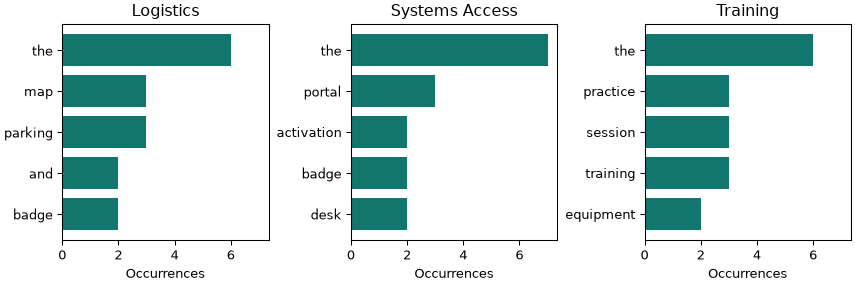

In [2]:
token_rows = [
    (document["category"], token)
    for document in corpus
    for token in tokenize(document["text"])
]
tokens = pl.DataFrame(token_rows, schema=["category", "token"], orient="row")
global_counts = (
    tokens.group_by("token").len().sort(["len", "token"], descending=[True, False])
)
category_counts = (
    tokens.group_by("category", "token")
    .len()
    .sort(["category", "len", "token"], descending=[False, True, False])
)

bigrams = Counter()
for document in corpus:
    words = tokenize(document["text"])
    bigrams.update(" ".join(pair) for pair in pairwise(words))
print("Global top tokens:", global_counts.head(6).rows())
print("Most frequent bigrams:", bigrams.most_common(6))
for target in ("badge", "training"):
    print(
        f"Neighbors of {target} (radius 3):",
        nearby_words(corpus, target, 3).most_common(6),
    )

categories = sorted({document["category"] for document in corpus})
fig, axes = plt.subplots(
    1, len(categories), figsize=(9, 3), sharex=True, layout="constrained"
)
for category, ax in zip(categories, axes):
    top = category_counts.filter(pl.col("category") == category).head(5).reverse()
    ax.barh(top["token"].to_list(), top["len"].to_list(), color="#13766e")
    ax.set_title(category.title())
    ax.set_xlabel("Occurrences")
plt.show()

## Interpretation

Repeated pairs such as parking map and practice session help identify concrete topics. Badge occurs in logistics and systems access, so neighboring words help distinguish pickup from activation. These fictional examples illustrate the method. Frequency alone cannot tell whether comments are positive or negative or how common a problem is among actual fellows.